## **CSE330 Section 15 Special Assignment Summer 2024** (Total Marks : 10)

In [108]:
Name = "Muaz Ibne Ashraf"
ID = "21101177"
Section = "15"

# Question 01 [6 Marks]

Let $f(x)$ be a function of $x$.

$$f(x) = x^5 + 2.5x^4 - 2x^3 -6x^2 + \frac{x}{2} + 2\tag{2.1}$$

a. Find the actual roots of $f(x)$ and print them.

b. Plot the function for $-2.5 \le x \le 1.5$, also point out the the found roots in the plot

c. The following $g_{1}(x)$ is given which is derived from Eq(2.1), \\
   Use Contraction Mapping Theorem and calculate the value of λ for the given $g(x)$ $$g_{1}(x)= \frac{1}{2}(-x^5 - 2.5x^4 + 2x^3 + 6x^2 - 2)\tag{2.2}$$

d. Compute the convergence/divergence table using all the calculated roots for the given $g_{1}(x)$ and prove the whole $g_{1}(x)$ is divergent

e. Derive 2 more separate $g(x)$ from the given $f(x)$

f. Apply Fixed Point Method on the rest of the $g(x)$s and find the approprate roots, show 20 iterations for each $g(x)$ for $x_{0}$ = 0.8 and show the convergence table using data from each iteration

g. Plot the $g(x)$s where actual roots were found

In [109]:
#a
import numpy as np

coeffs = [1, 2.5, -2, -6, 0.5, 2]
roots = np.roots(coeffs)

actl_roots = []
for root in roots:
    if np.isreal(root):
        actl_roots.append(round(root.real, 6))

print("The actual roots of f(x) are:")
for root in actl_roots:
    print(f"{root}")

The actual roots of f(x) are:
-2.220276
1.375268
-1.618034
0.618034
-0.654992


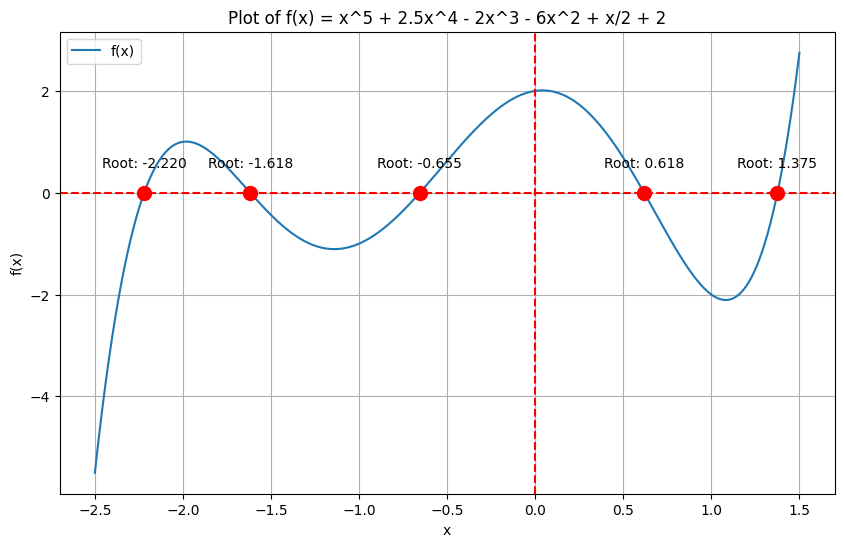

In [110]:
#b
import matplotlib.pyplot as plt

x = np.linspace(-2.5, 1.5, 1000)
y = f(x)

plt.figure(figsize=(10, 6))
plt.plot(x, y, label='f(x)')

plt.axhline(y=0, color='r', linestyle='--')
plt.axvline(x=0, color='r', linestyle='--')

roots = [-2.220276, 1.375268, -1.618034, 0.618034, -0.654992]
for root in roots:
    plt.plot(root, 0, 'ro', markersize=10)
    plt.text(root, 0.5, f'Root: {root:.3f}', ha='center')

plt.title('Plot of f(x) = x^5 + 2.5x^4 - 2x^3 - 6x^2 + x/2 + 2')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()

In [111]:
#c

def g1_prime(x):
  return -2.5*x**4 - 5*x**3 + 3*x**2 + 6*x

intervals = [(-3, -2.5), (-1.5, -0.5), (0.5, 1)]

max_lambda = 0
for interval in intervals:
  x = np.linspace(interval[0], interval[1], 1000)
  lambda_values = np.abs(g1_prime(x))
  max_lambda = max(max_lambda, np.max(lambda_values))

print(f"The maximum value of λ is approximately {max_lambda:.6f}")

The maximum value of λ is approximately 58.500000


In [112]:
#d
def g1_prime(x):
    return -2.5*x**4 - 5*x**3 + 3*x**2 + 6*x

print("Convergence/Divergence table for g₁(x):")
print("Root\t\t|g₁'(x)|\tConvergence")
print("-" * 40)
for root in roots:
    derivative_value = abs(g1_prime(root))
    convergence = "Convergent" if derivative_value < 1 else "Divergent"
    print(f"{root:.6f}\t{derivative_value:.6f}\t{convergence}")

print("\ng₁(x) is divergent overall because it's divergent for at least one root.")

Convergence/Divergence table for g₁(x):
Root		|g₁'(x)|	Convergence
----------------------------------------
-2.220276	4.560153	Divergent
1.375268	8.023081	Divergent
-1.618034	2.190983	Divergent
0.618034	3.309017	Divergent
-0.654992	1.698037	Divergent

g₁(x) is divergent overall because it's divergent for at least one root.


In [ ]:
#e
'''
f(x) = x^5 + 2.5x^4 - 2x^3 - 6x^2 + 0.5x + 2 = 0

For g2(x):
x^5 + 2.5x^4 - 2x^3 - 6x^2 + 0.5x + 2 = 0
x^5 = -2.5x^4 + 2x^3 + 6x^2 - 0.5x - 2
x = (-2.5x^4 + 2x^3 + 6x^2 - 0.5x - 2)^(1/5)
g₂(x) = (2x³ + 6x² - 0.5x - 2)^(1/5)

For g3(x):
x^5 + 2.5x^4 - 2x^3 - 6x^2 + 0.5x + 2 = 0
6x^2 = -x^5 - 2.5x^4 + 2x^3 - 0.5x - 2
x^2 = (-x^5 - 2.5x^4 + 2x^3 - 0.5x - 2) / 6
x = (-x⁵ - 2.5x⁴ + 2x³ + 0.5x + 2)^(1/6)
g₃(x) = (-x⁵ - 2.5x⁴ + 2x³ + 0.5x + 2)^(1/6)
'''

In [114]:
#f
def g2(x):
  return (2*x**3 + 6*x**2 - 0.5*x - 2)**(1/5)

def g3(x):
  return (-x**5 - 2.5*x**4 + 2*x**3 + 0.5*x + 2)**(1/6)

xx = 0.8
iterations = 20

for g, name in [(g2, "g₂(x)"), (g3, "g₃(x)")]:
  print(f"\nFixed Point Iterations for {name}:")
  print("n\tx_n\t\t|x_n - x_{n-1}|")
  print("-" * 40)

  xx_prev = xx
  for i in range(iterations):
    x = g(xx_prev)
    diff = abs(x - xx_prev)
    print(f"{i+1}\t{x:.8f}\t{diff:.8f}")
    xx_prev = x


Fixed Point Iterations for g₂(x):
n	x_n		|x_n - x_{n-1}|
----------------------------------------
1	1.19764510	0.39764510
2	1.56683022	0.36918512
3	1.81395005	0.24711983
4	1.95792682	0.14397677
5	2.03655459	0.07862777
6	2.07815463	0.04160004
7	2.09981729	0.02166266
8	2.11100738	0.01119009
9	2.11676409	0.00575671
10	2.11971942	0.00295533
11	2.12123497	0.00151555
12	2.12201175	0.00077678
13	2.12240977	0.00039802
14	2.12261368	0.00020391
15	2.12271814	0.00010446
16	2.12277165	0.00005351
17	2.12279907	0.00002741
18	2.12281311	0.00001404
19	2.12282030	0.00000719
20	2.12282398	0.00000368

Fixed Point Iterations for g₃(x):
n	x_n		|x_n - x_{n-1}|
----------------------------------------
1	1.12912703	0.32912703
2	0.75957991+0.43854366j	0.57348550
3	1.23621480+0.00161205j	0.64659884
4	0.99848746-0.57327211j	0.62209813
5	1.36850257+0.05301610j	0.72742567
6	1.19394717-0.61517205j	0.69061204
7	1.47797212+0.13636583j	0.80341730
8	1.34564498-0.61249936j	0.76046665
9	1.55554443+0.22165760j	0.86016022

<ipython-input-114-dd1b95ce27f2>:3: RuntimeWarning: invalid value encountered in power
  return (2*x**3 + 6*x**2 - 0.5*x - 2)**(1/5)
<ipython-input-114-dd1b95ce27f2>:6: RuntimeWarning: invalid value encountered in power
  return (-x**5 - 2.5*x**4 + 2*x**3 + 0.5*x + 2)**(1/6)


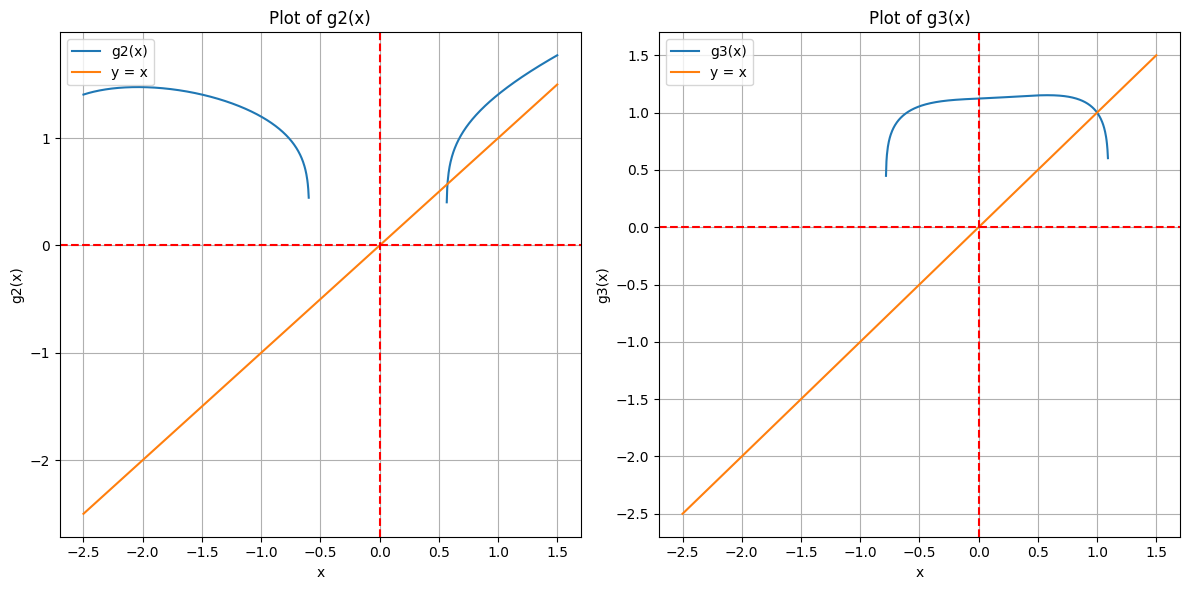

In [115]:
#g
x = np.linspace(-2.5, 1.5, 1000)

y2 = g2(x)
y3 = g3(x)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.plot(x, y2, label='g2(x)')
ax1.plot(x, x, label='y = x')
ax1.axhline(y=0, color='r', linestyle='--')
ax1.axvline(x=0, color='r', linestyle='--')
ax1.set_title('Plot of g2(x)')
ax1.set_xlabel('x')
ax1.set_ylabel('g2(x)')
ax1.legend()
ax1.grid(True)

ax2.plot(x, y3, label='g3(x)')
ax2.plot(x, x, label='y = x')
ax2.axhline(y=0, color='r', linestyle='--')
ax2.axvline(x=0, color='r', linestyle='--')
ax2.set_title('Plot of g3(x)')
ax2.set_xlabel('x')
ax2.set_ylabel('g3(x)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

#Question 02 [4 Marks]

Compute the Second Degree Richarson Extrapolation, `D^{2}` at `x = 1` and `h = 0.4` when the formula is derived using `h -> h/3`.

**N.B.** You can use the previously learned methods while solving the problem.

In [119]:
def f(x):
    return np.sin(x)

def sd(f, x, h):
    return (f(x + h) - 2 * f(x) + f(x - h)) / h**2

h = 0.4
x = 1
D2_h = sd(f, x, h)
D2_h3 = sd(f, x, h/3)

D2 = (9 * D2_h3 - D2_h) / 8

print(f"Second Degree Richardson Extrapolation at x = {x} and h = {h} is {D2}")

Second Degree Richardson Extrapolation at x = 1 and h = 0.4 is -0.8414643572172259
